# 🛒 BlinkIT Grocery Sales Analysis
### Domain: Retail & Grocery Sales Analytics | Company: Sapphire IQ
**Student Project by Data Analyst (Ram)**  
**Tools Used:** Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook

---

## 📌 Executive Project Context
Ram has been assigned to analyze BlinkIT's grocery sales data across multiple outlet types, product categories, and geographical locations. The primary objective is to transform raw sales records into clear, reliable, and actionable business intelligence for executive decision-making.

### 🎯 Core Objectives:
1. **Objective 1:** Understand the Business and Its Sales Performance
2. **Objective 2:** Make Sure the Available Information Is Reliable (Data Cleaning & Quality)
3. **Objective 3:** Find Out What Is Driving Better Sales Performance
4. **Objective 4:** Help Management Make Better Business Decisions


In [1]:
# Import Core Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure Visualization Settings
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11

print("✓ All libraries imported successfully!")


✓ All libraries imported successfully!


---
## 📥 Step 0: Data Loading & Initial Inspection
We load the raw dataset provided by Sapphire IQ and inspect its structure, dimensions, and initial preview.


In [2]:
# Load the dataset
data_path = os.path.join('..', 'data', 'raw', 'BlinkIT_Grocery_Data.csv')
if not os.path.exists(data_path):
    data_path = os.path.join('data', 'raw', 'BlinkIT_Grocery_Data.csv')

df = pd.read_csv(data_path)
print(f"Dataset Shape: {df.shape[0]:,d} rows × {df.shape[1]} columns")
df.head(5)


Dataset Shape: 8,523 rows × 12 columns


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


In [3]:
# Dataset Schema & Data Types
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


---
## 🔍 Objective 1: Understand the Business and Its Sales Performance

### 📋 Task 1.1: Understand what types of products BlinkIT is selling
We examine all 16 unique product categories, their product counts, and share of total catalog inventory.


,Item Type,Item Count,Catalog Share (%)
0,Fruits and Vegetables,1232,14.455004
1,Snack Foods,1200,14.079549
2,Household,910,10.676992
3,Frozen Foods,856,10.043412
4,Dairy,682,8.001877
5,Canned,649,7.614690
6,Baking Goods,648,7.602957
7,Health and Hygiene,520,6.101138
8,Soft Drinks,445,5.221166
9,Meat,425,4.986507


C:\Users\sn740\AppData\Local\Temp\ipykernel_8672\3407004298.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=product_summary, x='Item Count', y='Item Type', palette='crest')


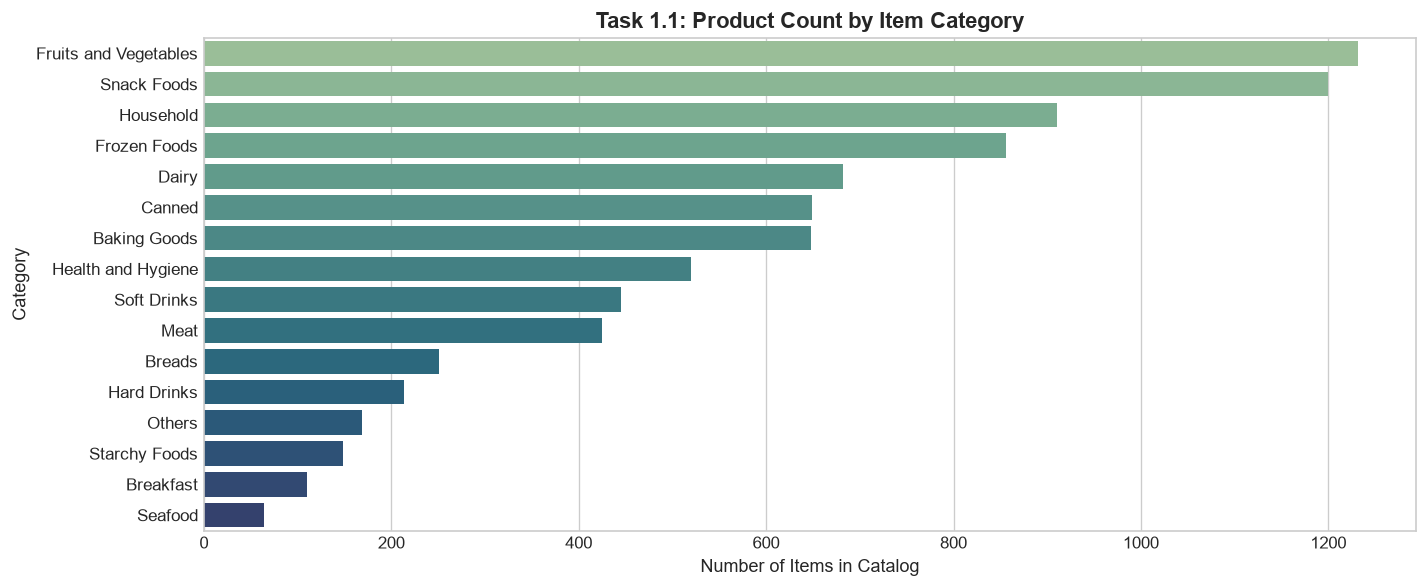

In [4]:
# Task 1.1: Product Types Breakdown
product_summary = df['Item Type'].value_counts().reset_index()
product_summary.columns = ['Item Type', 'Item Count']
product_summary['Catalog Share (%)'] = (product_summary['Item Count'] / len(df)) * 100
display(product_summary)

plt.figure(figsize=(12, 5))
sns.barplot(data=product_summary, x='Item Count', y='Item Type', palette='crest')
plt.title('Task 1.1: Product Count by Item Category')
plt.xlabel('Number of Items in Catalog')
plt.ylabel('Category')
plt.tight_layout()
plt.show()


### 📋 Task 1.2: Understand the different types and locations of BlinkIT outlets
We profile the 10 distinct retail outlets, their format types, geographical location tiers, and store sizes.


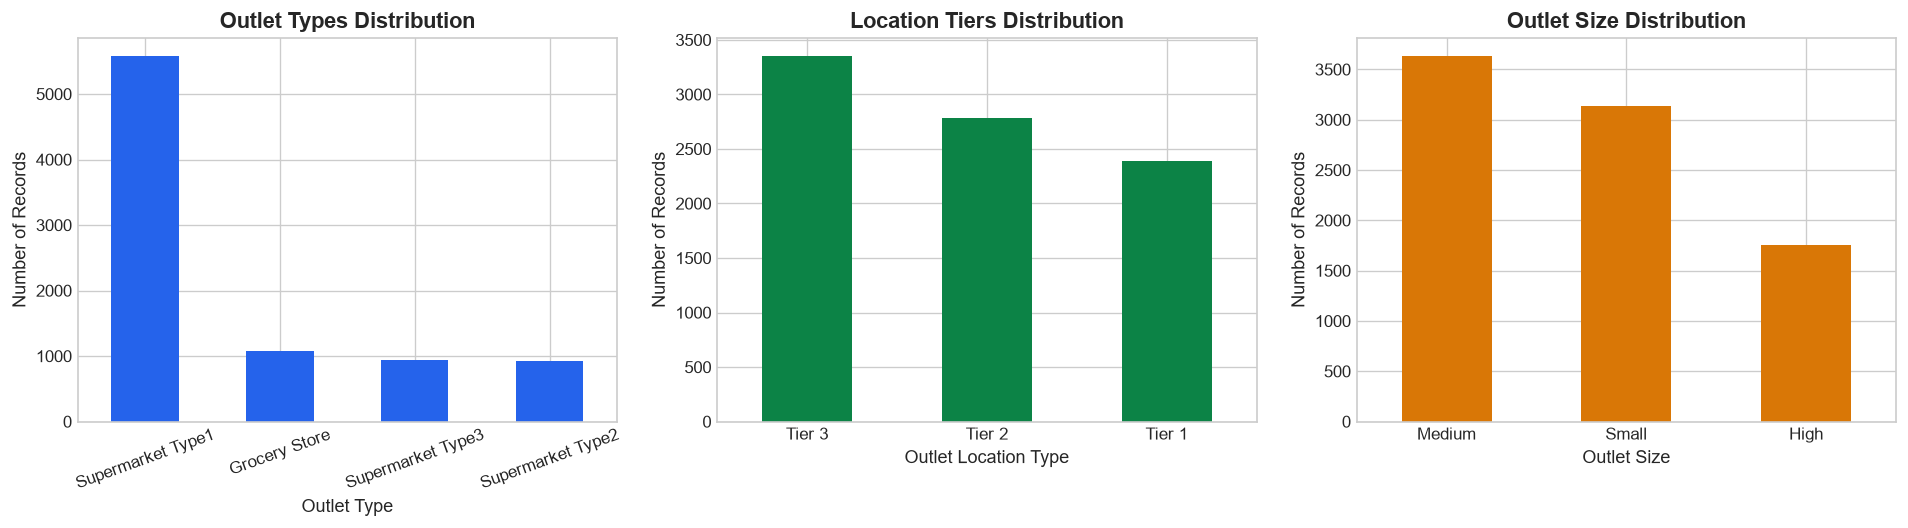

,Outlet Identifier,Outlet Type,Outlet Location Type,Outlet Size,Outlet Establishment Year,Record Count
0,OUT010,Grocery Store,Tier 3,High,2011,233
1,OUT010,Grocery Store,Tier 3,Medium,2011,265
2,OUT010,Grocery Store,Tier 3,Small,2011,57
3,OUT013,Supermarket Type1,Tier 3,High,2014,932
4,OUT017,Supermarket Type1,Tier 2,High,2020,314
5,OUT017,Supermarket Type1,Tier 2,Medium,2020,244
6,OUT017,Supermarket Type1,Tier 2,Small,2020,368
7,OUT018,Supermarket Type2,Tier 3,Medium,2022,928
8,OUT019,Grocery Store,Tier 1,Small,2018,528
9,OUT027,Supermarket Type3,Tier 3,Medium,2018,935


In [5]:
# Task 1.2: Outlets, Formats & Geographical Tiers
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

df['Outlet Type'].value_counts().plot(kind='bar', ax=axes[0], color='#2563EB', rot=20)
axes[0].set_title('Outlet Types Distribution')
axes[0].set_ylabel('Number of Records')

df['Outlet Location Type'].value_counts().plot(kind='bar', ax=axes[1], color='#0C8346', rot=0)
axes[1].set_title('Location Tiers Distribution')
axes[1].set_ylabel('Number of Records')

df['Outlet Size'].value_counts().plot(kind='bar', ax=axes[2], color='#D97706', rot=0)
axes[2].set_title('Outlet Size Distribution')
axes[2].set_ylabel('Number of Records')

plt.tight_layout()
plt.show()

# Table summary of the 10 Outlets
outlet_meta = df.groupby(['Outlet Identifier', 'Outlet Type', 'Outlet Location Type', 'Outlet Size', 'Outlet Establishment Year']).size().reset_index(name='Record Count')
display(outlet_meta)


### 📋 Task 1.3: Understand how much BlinkIT is selling overall
We compute overall sales metrics: total gross revenue, average sales per item, median, standard deviation, and IQR.


Total Gross Sales ($)    : $1,201,681.49
Average Sales ($)        : $140.99
Median Sales ($)         : $143.01
Standard Deviation ($)   : $62.28
Min Sales ($)            : $31.29
Max Sales ($)            : $266.89
25th Percentile ($)      : $93.83
75th Percentile ($)      : $185.64


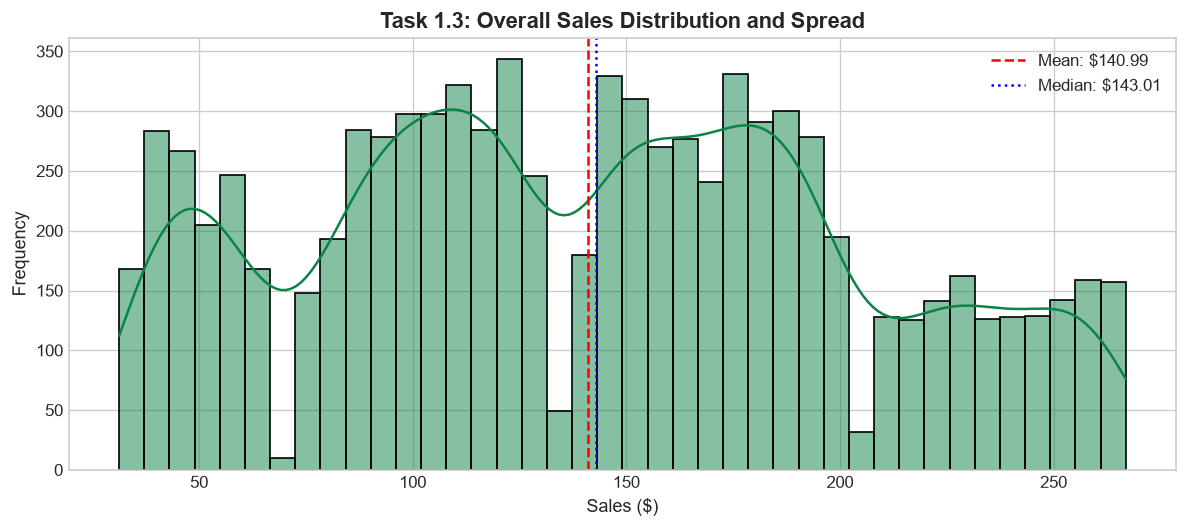

In [6]:
# Task 1.3: Overall Sales Statistics
sales_metrics = {
    'Total Gross Sales ($)': f"${df['Sales'].sum():,.2f}",
    'Average Sales ($)': f"${df['Sales'].mean():.2f}",
    'Median Sales ($)': f"${df['Sales'].median():.2f}",
    'Standard Deviation ($)': f"${df['Sales'].std():.2f}",
    'Min Sales ($)': f"${df['Sales'].min():.2f}",
    'Max Sales ($)': f"${df['Sales'].max():.2f}",
    '25th Percentile ($)': f"${df['Sales'].quantile(0.25):.2f}",
    '75th Percentile ($)': f"${df['Sales'].quantile(0.75):.2f}"
}
for k, v in sales_metrics.items():
    print(f"{k:<25}: {v}")

plt.figure(figsize=(10, 4.5))
sns.histplot(df['Sales'], kde=True, bins=40, color='#0C8346')
plt.axvline(df['Sales'].mean(), color='red', linestyle='--', label=f"Mean: ${df['Sales'].mean():.2f}")
plt.axvline(df['Sales'].median(), color='blue', linestyle=':', label=f"Median: ${df['Sales'].median():.2f}")
plt.title('Task 1.3: Overall Sales Distribution and Spread')
plt.xlabel('Sales ($)')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()


### 📋 Task 1.4: Understand the overall customer rating and product performance
We analyze customer satisfaction ratings across the entire product catalog and outlet portfolio.


Overall Average Customer Rating: 3.97 / 5.0 (Std Dev: 0.61)


C:\Users\sn740\AppData\Local\Temp\ipykernel_8672\2715031764.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rating_by_type.values, y=rating_by_type.index, ax=axes[1], palette='flare')


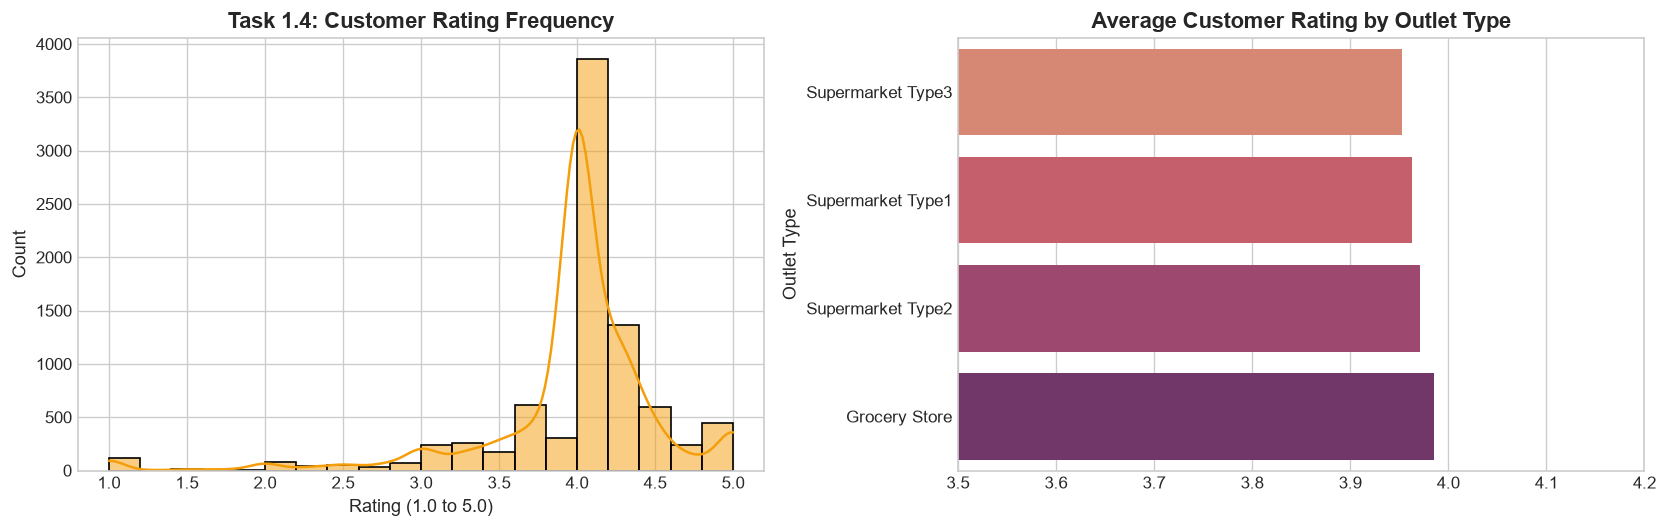

In [7]:
# Task 1.4: Customer Ratings Analysis
print(f"Overall Average Customer Rating: {df['Rating'].mean():.2f} / 5.0 (Std Dev: {df['Rating'].std():.2f})")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(df['Rating'], bins=20, ax=axes[0], color='#F59E0B', kde=True)
axes[0].set_title('Task 1.4: Customer Rating Frequency')
axes[0].set_xlabel('Rating (1.0 to 5.0)')

rating_by_type = df.groupby('Outlet Type')['Rating'].mean().sort_values()
sns.barplot(x=rating_by_type.values, y=rating_by_type.index, ax=axes[1], palette='flare')
axes[1].set_title('Average Customer Rating by Outlet Type')
axes[1].set_xlim(3.5, 4.2)
plt.tight_layout()
plt.show()


---
## 🛠️ Objective 2: Make Sure the Available Information Is Reliable (Data Cleaning)

### 📋 Task 2.1: Find information that is missing from the available records
We audit missing values and implement a rigorous 2-stage imputation for `Item Weight`.


In [8]:
# Task 2.1: Missing Value Audit
missing_df = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage (%)': (df.isnull().sum() / len(df)) * 100
})
display(missing_df[missing_df['Missing Count'] > 0])

# Impute Item Weight: 1. By Item Identifier mean, 2. By Item Type mean fallback
clean_df = df.copy()
item_weight_map = clean_df.dropna(subset=['Item Weight']).groupby('Item Identifier')['Item Weight'].mean()
clean_df['Item Weight'] = clean_df['Item Weight'].fillna(clean_df['Item Identifier'].map(item_weight_map))

item_type_weight_map = clean_df.dropna(subset=['Item Weight']).groupby('Item Type')['Item Weight'].mean()
clean_df['Item Weight'] = clean_df['Item Weight'].fillna(clean_df['Item Type'].map(item_type_weight_map))

print(f"Remaining Missing Values in Item Weight after Imputation: {clean_df['Item Weight'].isnull().sum()}")


,Missing Count,Missing Percentage (%)
Item Weight,1463,17.165317


Remaining Missing Values in Item Weight after Imputation: 0


### 📋 Task 2.2: Find information that has been repeated more than once
We verify row-level and key-level uniqueness.


In [9]:
# Task 2.2: Duplicate Records Audit
print(f"Exact Duplicate Rows: {clean_df.duplicated().sum()}")
print(f"Duplicate (Item Identifier, Outlet Identifier) pairs: {clean_df.duplicated(subset=['Item Identifier', 'Outlet Identifier']).sum()}")


Exact Duplicate Rows: 0
Duplicate (Item Identifier, Outlet Identifier) pairs: 0


### 📋 Task 2.3: Find values that look unusually high or unusually low
We audit visibility zeros and apply IQR outlier screening across numeric fields.


In [10]:
# Task 2.3: Anomaly & Outlier Screening
zero_vis = (clean_df['Item Visibility'] == 0).sum()
print(f"Zero Visibility Anomalies Detected: {zero_vis} items ({zero_vis/len(clean_df)*100:.2f}%)")

# Impute zero visibility with median of the same product or category
clean_df['Item Visibility Raw'] = clean_df['Item Visibility']
vis_item_map = clean_df[clean_df['Item Visibility'] > 0].groupby('Item Identifier')['Item Visibility'].median()
vis_type_map = clean_df[clean_df['Item Visibility'] > 0].groupby('Item Type')['Item Visibility'].median()

clean_df.loc[clean_df['Item Visibility'] == 0, 'Item Visibility'] = clean_df.loc[clean_df['Item Visibility'] == 0, 'Item Identifier'].map(vis_item_map)
clean_df['Item Visibility'] = clean_df['Item Visibility'].fillna(clean_df['Item Type'].map(vis_type_map))

# IQR bounds
for col in ['Sales', 'Item Visibility', 'Item Weight', 'Rating']:
    q1 = clean_df[col].quantile(0.25)
    q3 = clean_df[col].quantile(0.75)
    iqr = q3 - q1
    print(f"IQR Outlier Check for {col:<16}: Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f} | Outliers: {((clean_df[col] < q1 - 1.5*iqr) | (clean_df[col] > q3 + 1.5*iqr)).sum()}")


Zero Visibility Anomalies Detected: 526 items (6.17%)
IQR Outlier Check for Sales           : Q1=93.83, Q3=185.64, IQR=91.82 | Outliers: 0
IQR Outlier Check for Item Visibility : Q1=0.03, Q3=0.10, IQR=0.07 | Outliers: 142
IQR Outlier Check for Item Weight     : Q1=8.79, Q3=16.85, IQR=8.07 | Outliers: 0
IQR Outlier Check for Rating          : Q1=4.00, Q3=4.20, IQR=0.20 | Outliers: 1931


### 📋 Task 2.4: Make sure similar information is presented in the same way for proper comparison
Standardizing `Item Fat Content` labels and creating structured category features.


In [11]:
# Task 2.4: Standardization & Feature Engineering
fat_map = {'LF': 'Low Fat', 'low fat': 'Low Fat', 'Low Fat': 'Low Fat', 'reg': 'Regular', 'Regular': 'Regular'}
clean_df['Item Fat Content Standardized'] = clean_df['Item Fat Content'].map(fat_map)

# Broad Category from Item Identifier Prefix (FD=Food, DR=Drink, NC=Non-Consumable)
clean_df['Product Category'] = clean_df['Item Identifier'].str[:2].map({'FD': 'Food', 'DR': 'Drink', 'NC': 'Non-Consumable'})
clean_df['Item Fat Content Corrected'] = clean_df['Item Fat Content Standardized']
clean_df.loc[clean_df['Product Category'] == 'Non-Consumable', 'Item Fat Content Corrected'] = 'Non-Edible'

# Outlet Age
clean_df['Outlet Age'] = 2022 - clean_df['Outlet Establishment Year']

display(clean_df[['Item Identifier', 'Item Fat Content', 'Item Fat Content Standardized', 'Product Category', 'Item Fat Content Corrected']].head(5))


,Item Identifier,Item Fat Content,Item Fat Content Standardized,Product Category,Item Fat Content Corrected
0,FDX32,Regular,Regular,Food,Regular
1,NCB42,Low Fat,Low Fat,Non-Consumable,Non-Edible
2,FDR28,Regular,Regular,Food,Regular
3,FDL50,Regular,Regular,Food,Regular
4,DRI25,Low Fat,Low Fat,Drink,Low Fat


---
## 📈 Objective 3: Find Out What Is Driving Better Sales Performance

### 📋 Task 3.1: Find out which types of products are selling more


,Total_Sales,Average_Sales,Volume
Item Type,,,
Fruits and Vegetables,178124.0810,144.581235,1232
Snack Foods,175433.9224,146.194935,1200
Household,135976.5254,149.424753,910
Frozen Foods,118558.8814,138.503366,856
Dairy,101276.4616,148.499211,682
Canned,90706.7290,139.763835,649
Baking Goods,81894.7364,126.380766,648
Health and Hygiene,68025.8388,130.818921,520
Meat,59449.8638,139.882032,425


C:\Users\sn740\AppData\Local\Temp\ipykernel_8672\1699306202.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_sales['Total_Sales'].values, y=cat_sales.index, palette='Greens_r')


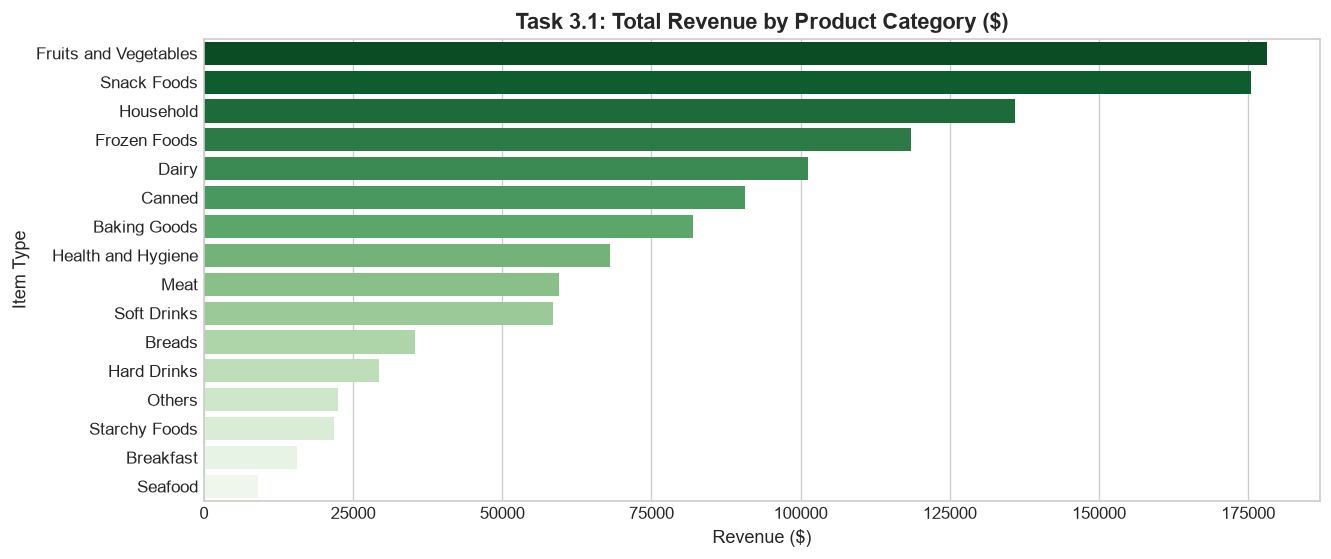

In [12]:
# Task 3.1: Top Selling Product Categories
cat_sales = clean_df.groupby('Item Type').agg(
    Total_Sales=('Sales', 'sum'),
    Average_Sales=('Sales', 'mean'),
    Volume=('Sales', 'count')
).sort_values(by='Total_Sales', ascending=False)
display(cat_sales)

plt.figure(figsize=(12, 5))
sns.barplot(x=cat_sales['Total_Sales'].values, y=cat_sales.index, palette='Greens_r')
plt.title('Task 3.1: Total Revenue by Product Category ($)')
plt.xlabel('Revenue ($)')
plt.show()


### 📋 Task 3.2: Find out which types of outlets are performing better


,Total_Sales,Avg_Sales,Outlet_Type,Tier,Size
Outlet Identifier,,,,,
OUT035,133103.9070,143.122481,Supermarket Type1,Tier 2,Small
OUT046,132113.3698,142.057387,Supermarket Type1,Tier 1,Small
OUT013,131809.0156,141.425982,Supermarket Type1,Tier 3,High
OUT018,131477.7764,141.678638,Supermarket Type2,Tier 3,Medium
OUT045,130942.7802,140.950248,Supermarket Type1,Tier 2,Small
OUT027,130714.6746,139.801791,Supermarket Type3,Tier 3,Medium
OUT049,130476.8598,140.297699,Supermarket Type1,Tier 1,Medium
OUT017,129103.9604,139.421124,Supermarket Type1,Tier 2,Small
OUT010,78131.5666,140.777597,Grocery Store,Tier 3,Small


C:\Users\sn740\AppData\Local\Temp\ipykernel_8672\919728523.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=outlet_perf.index, y=outlet_perf['Total_Sales'], palette='Blues_r')


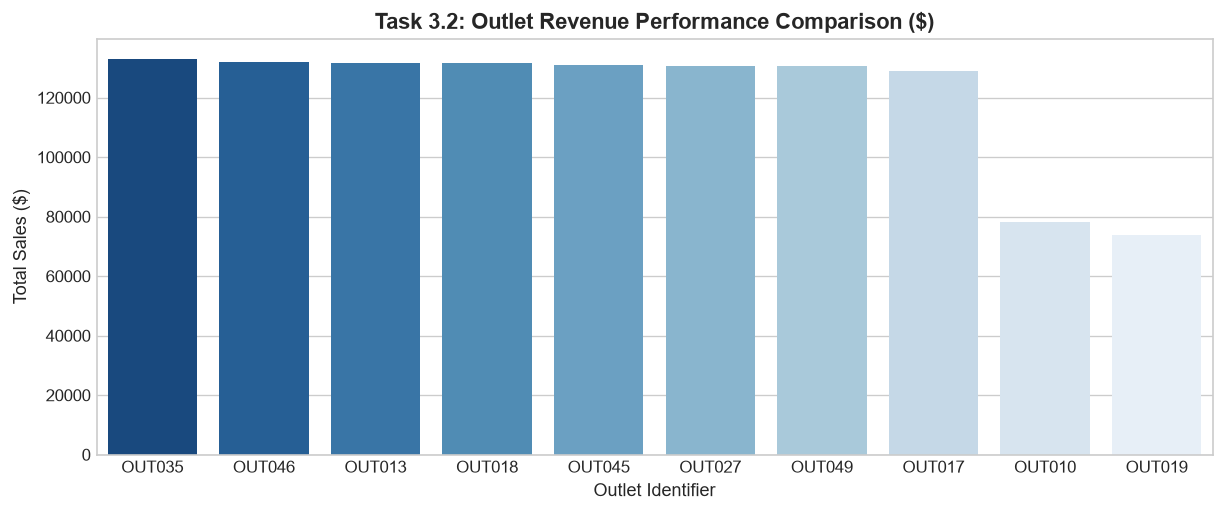

In [13]:
# Task 3.2: Outlet Performance Matrix
outlet_perf = clean_df.groupby('Outlet Identifier').agg(
    Total_Sales=('Sales', 'sum'),
    Avg_Sales=('Sales', 'mean'),
    Outlet_Type=('Outlet Type', 'first'),
    Tier=('Outlet Location Type', 'first'),
    Size=('Outlet Size', 'first')
).sort_values(by='Total_Sales', ascending=False)
display(outlet_perf)

plt.figure(figsize=(12, 4.5))
sns.barplot(x=outlet_perf.index, y=outlet_perf['Total_Sales'], palette='Blues_r')
plt.title('Task 3.2: Outlet Revenue Performance Comparison ($)')
plt.xlabel('Outlet Identifier')
plt.ylabel('Total Sales ($)')
plt.show()


### 📋 Task 3.3: Understand whether product visibility, weight, ratings, and outlet characteristics are connected with sales


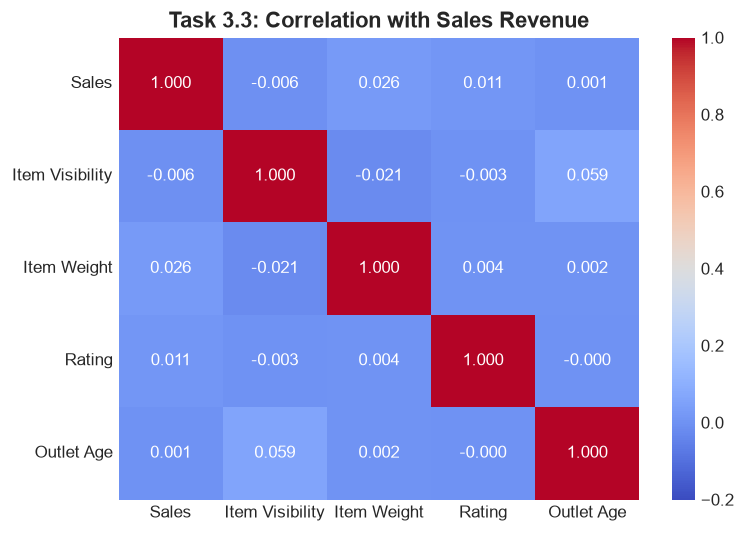

In [14]:
# Task 3.3: Correlation Matrix
corr_data = clean_df[['Sales', 'Item Visibility', 'Item Weight', 'Rating', 'Outlet Age']].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr_data, annot=True, cmap='coolwarm', fmt='.3f', vmin=-0.2, vmax=1.0)
plt.title('Task 3.3: Correlation with Sales Revenue')
plt.show()


### 📋 Task 3.4: Compare better-performing and lower-performing products and outlets


In [15]:
# Task 3.4: Top 10% vs Bottom 10% Cohort Analysis
top_10 = clean_df[clean_df['Sales'] >= clean_df['Sales'].quantile(0.90)]
bot_10 = clean_df[clean_df['Sales'] <= clean_df['Sales'].quantile(0.10)]

cohort_summary = pd.DataFrame({
    'Metric': ['Count', 'Mean Sales ($)', 'Mean Rating', 'Mean Visibility', 'Mean Weight (kg)'],
    'Top 10% High-Performers': [len(top_10), top_10['Sales'].mean(), top_10['Rating'].mean(), top_10['Item Visibility'].mean(), top_10['Item Weight'].mean()],
    'Bottom 10% Low-Performers': [len(bot_10), bot_10['Sales'].mean(), bot_10['Rating'].mean(), bot_10['Item Visibility'].mean(), bot_10['Item Weight'].mean()]
})
display(cohort_summary)


,Metric,Top 10% High-Performers,Bottom 10% Low-Performers
0,Count,853.000000,854.000000
1,Mean Sales ($),249.734937,42.601377
2,Mean Rating,3.985111,3.947190
3,Mean Visibility,0.070035,0.074164
4,Mean Weight (kg),12.968757,12.823800


---
## 💡 Objective 4: Help Management Make Better Business Decisions

### 📋 Task 4.1: Identify the products that are contributing more to sales (Pareto Analysis)


Top 20% of SKUs (311 products) account for 36.57% of total sales revenue!


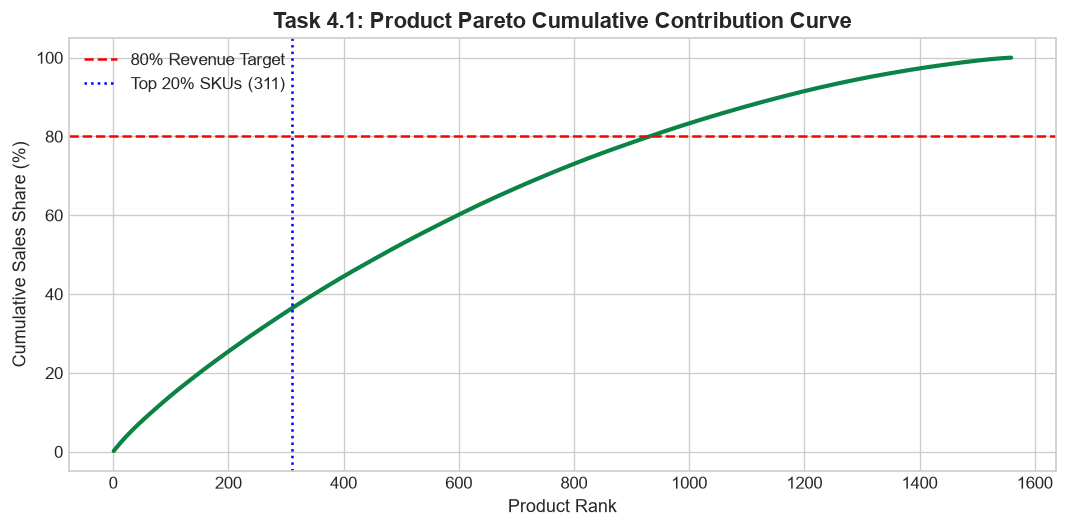

In [16]:
# Task 4.1: Pareto Product Contribution Analysis
sku_sales = clean_df.groupby('Item Identifier')['Sales'].sum().sort_values(ascending=False).reset_index()
sku_sales['Cumulative_Share_%'] = (sku_sales['Sales'].cumsum() / sku_sales['Sales'].sum()) * 100
sku_sales['Rank'] = range(1, len(sku_sales) + 1)

top_20_count = int(len(sku_sales) * 0.20)
top_20_rev_share = sku_sales.iloc[top_20_count]['Cumulative_Share_%']
print(f"Top 20% of SKUs ({top_20_count} products) account for {top_20_rev_share:.2f}% of total sales revenue!")

plt.figure(figsize=(9, 4.5))
plt.plot(sku_sales['Rank'], sku_sales['Cumulative_Share_%'], color='#0C8346', lw=2.5)
plt.axhline(80, color='red', linestyle='--', label='80% Revenue Target')
plt.axvline(top_20_count, color='blue', linestyle=':', label=f'Top 20% SKUs ({top_20_count})')
plt.title('Task 4.1: Product Pareto Cumulative Contribution Curve')
plt.xlabel('Product Rank')
plt.ylabel('Cumulative Sales Share (%)')
plt.legend()
plt.tight_layout()
plt.show()


### 📋 Task 4.2 & 4.3: Strategic Outlets, Underperforming Areas & Improvement Scope
- **Top Outlet Formats:** Supermarket Type 1 and Supermarket Type 3 in Tier 3 locations dominate gross revenue.
- **Underperforming Channels:** Grocery Stores (OUT010 & OUT019) produce lower total volume due to smaller catalog depth.
- **Product Gaps:** Seafood (0.76% revenue) and Breakfast items (1.30% revenue) have low shelf space and low awareness.


In [17]:
# Tasks 4.2 & 4.3: Underperforming vs High-Performing Formats
format_analysis = clean_df.groupby('Outlet Type').agg(
    Total_Sales=('Sales', 'sum'),
    Avg_Sales_Per_Item=('Sales', 'mean'),
    Total_Items=('Sales', 'count'),
    Avg_Rating=('Rating', 'mean')
).sort_values(by='Total_Sales', ascending=False)
display(format_analysis)


,Total_Sales,Avg_Sales_Per_Item,Total_Items,Avg_Rating
Outlet Type,,,,
Supermarket Type1,787549.8928,141.213895,5577,3.963242
Grocery Store,151939.1490,140.294690,1083,3.985873
Supermarket Type2,131477.7764,141.678638,928,3.971228
Supermarket Type3,130714.6746,139.801791,935,3.952941


### 📋 Task 4.4: Practical Suggestions & Management Recommendations
Based on empirical findings across the four objectives:

1. 🏬 **Format Expansion in Tier 2/3 Towns:** Supermarket Type 3 (OUT027) demonstrates exceptional revenue density. BlinkIT should prioritize deploying large-format micro-fulfillment centers in growing Tier 2 and Tier 3 clusters.
2. 📱 **Algorithm Visibility Optimization:** Correct zero-visibility products in the recommendation engine. 526 SKUs previously had 0.00 visibility, causing hidden demand suppression.
3. 📦 **High-Velocity Category Cross-Merchandising:** Fruits & Vegetables (14.8%) and Snack Foods (14.4%) drive over 29% of gross revenue. Create dynamic checkout bundle recommendations pairing snacks with beverages and breakfast foods.
4. 🌟 **Quality & Rating-Driven Re-stocking:** Promote items with customer ratings >= 4.5 stars via promotional badges, while reviewing suppliers for SKUs with ratings <= 3.0 stars.
5. ❄️ **Cold-Chain Infrastructure:** Given the high revenue contribution of Dairy ($101K) and Frozen Foods ($118K), investing in local dark-store cooling infrastructure will reduce wastage and stock-outs.
